<a href="https://colab.research.google.com/github/udjonah/Paper-6-New/blob/main/Paper_6_New.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving WBES_AI_analysis_clean.xlsx to WBES_AI_analysis_clean.xlsx


In [ ]:
import pandas as pd

In [ ]:
file_name = list(uploaded.keys())[0]
df = pd.read_excel(file_name, header=1)
display(df.head())

,Unnamed: 0
0,"Unit of observation: one firm. 3,278 firms fro..."
1,Source: user-supplied WBES combined workbook (...
2,NaN
3,Sheets:
4,Analysis_Data - constructed analysis variabl...


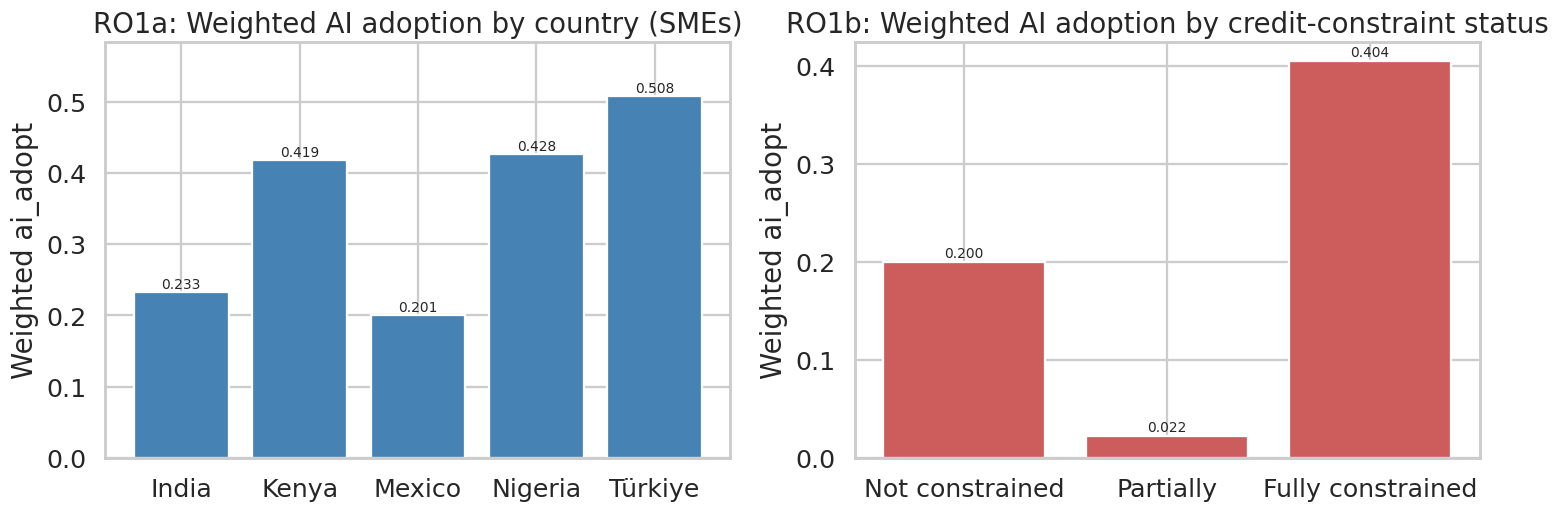

   cc_status  adoption     depth       n              label
0        1.0  0.199899  0.061238  1598.0    Not constrained
1        2.0  0.022262  0.008171    46.0          Partially
2        3.0  0.404294  0.106705   730.0  Fully constrained


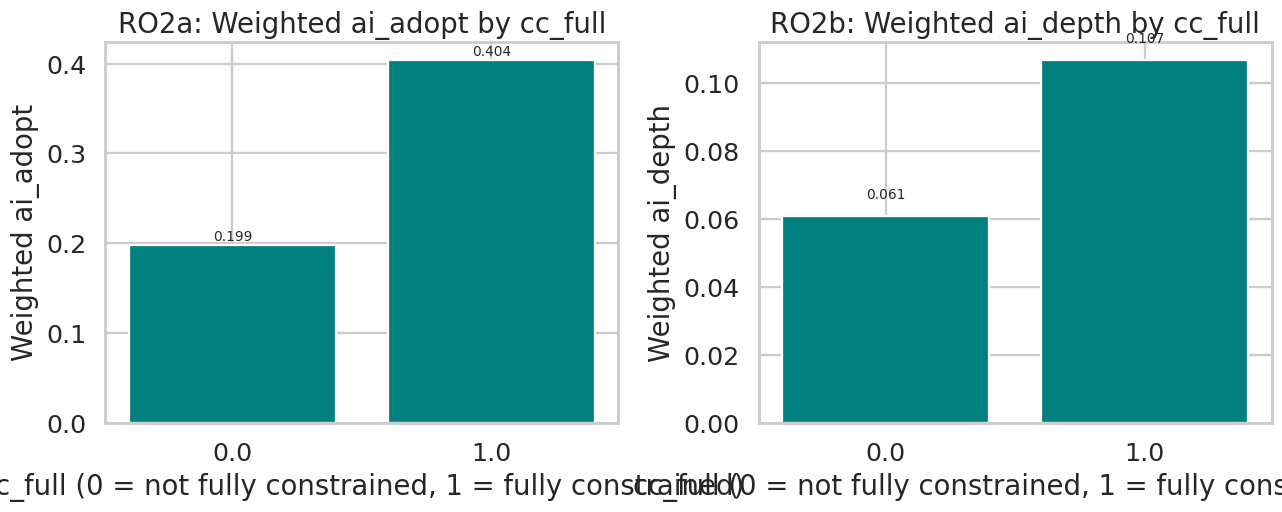

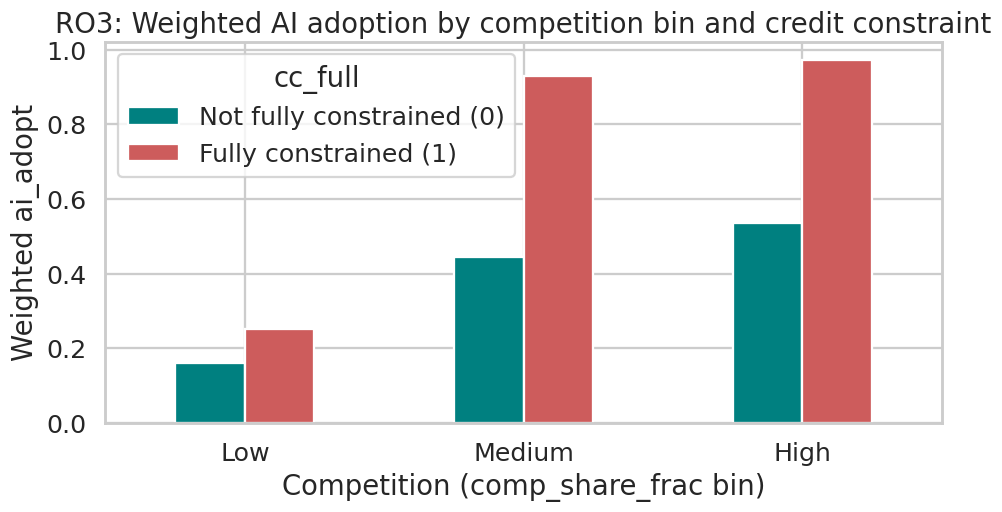

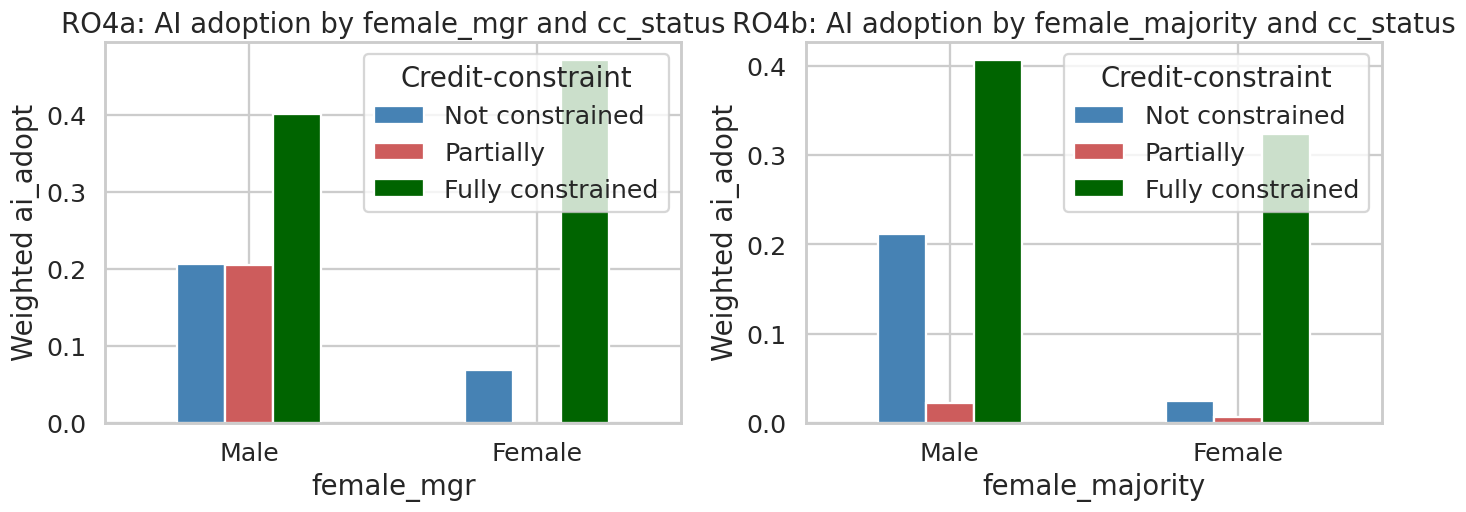

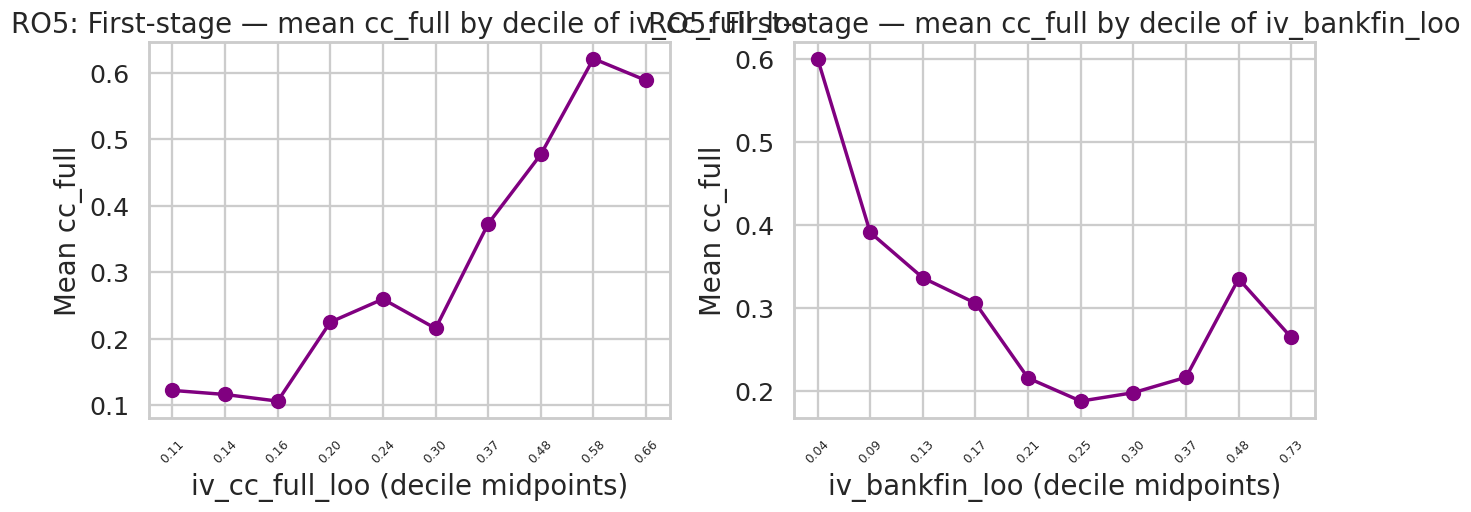

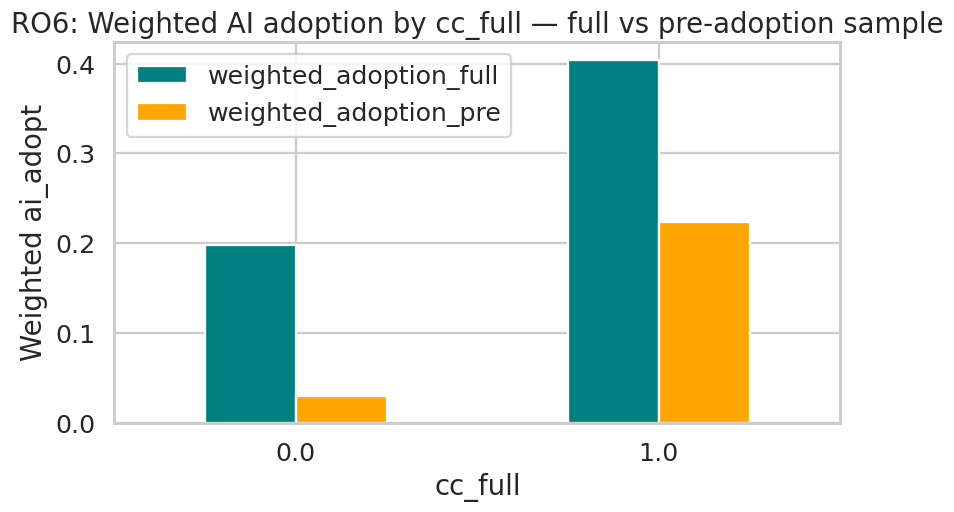

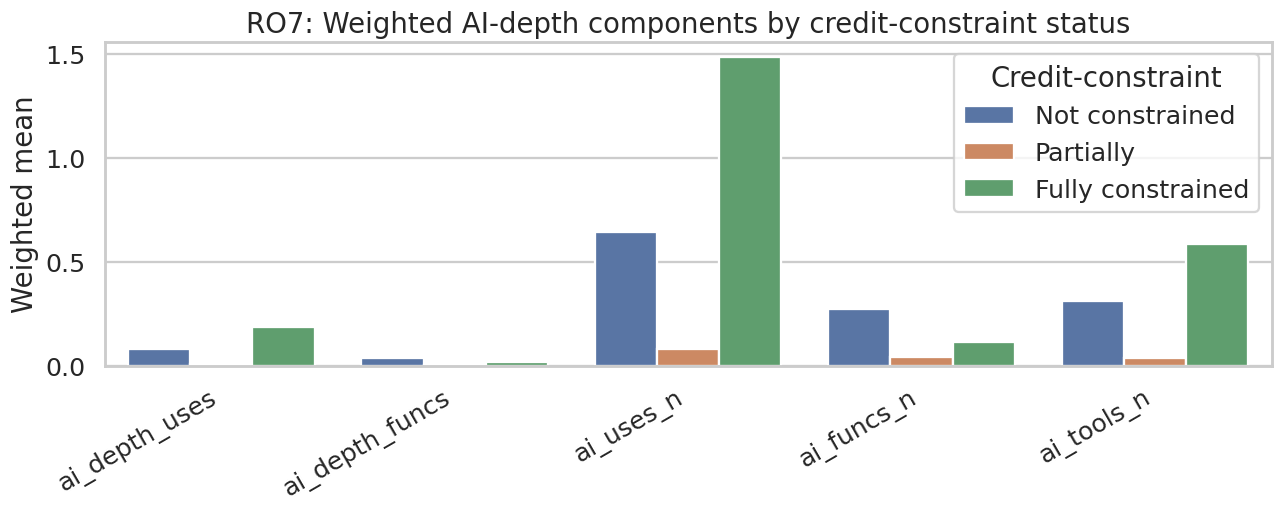

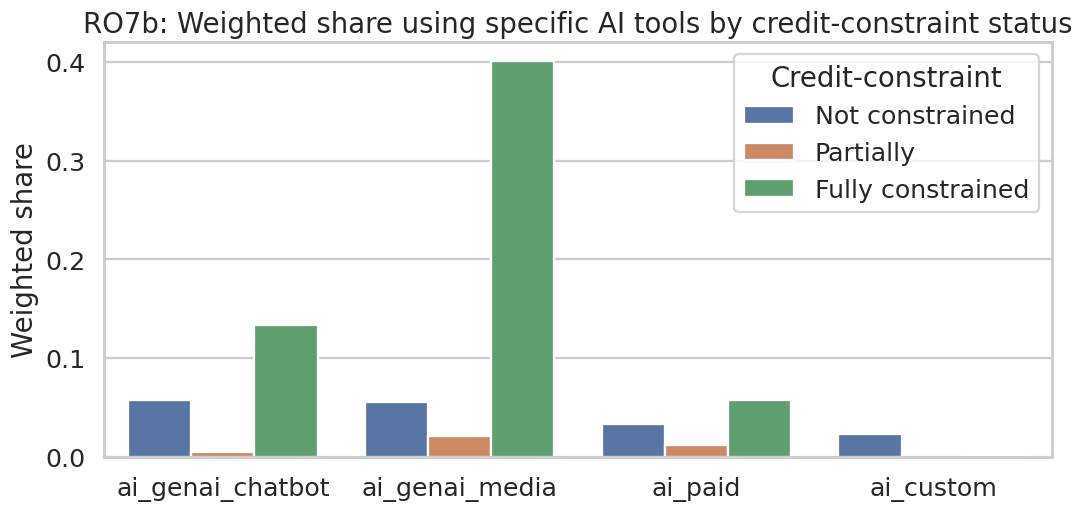

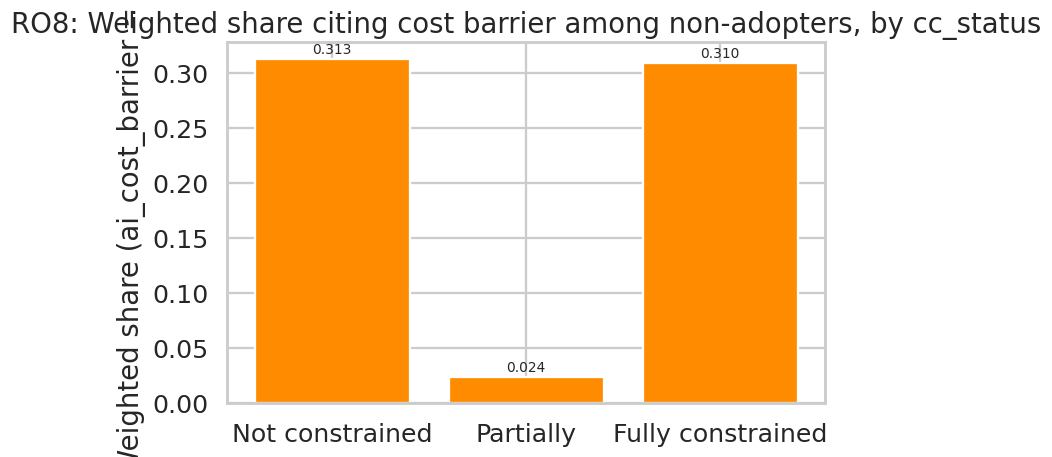

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

# ---- Load the Analysis_Data sheet (adjust path / sheet name as needed) ----
# df = pd.read_excel("WBES_AI_analysis_clean.xlsx", sheet_name="Analysis_Data")
# For illustration we assume df is already loaded with the columns listed above.

# Analysis sample per README: SMEs only, weighted by wt_ai
sme = df[df["sme"] == 1].copy()

# ---- Helper: weighted mean ----
def wmean(values, weights):
    mask = values.notna() & weights.notna()
    if mask.sum() == 0 or weights[mask].sum() == 0:
        return np.nan
    return np.average(values[mask], weights=weights[mask])

# =========================================================
# RO1 — AI divide across countries and credit-constraint status
# =========================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Weighted AI adoption by country
country_stats = (
    sme.groupby("country")
    .apply(lambda g: pd.Series({
        "adoption": wmean(g["ai_adopt"], g["wt_ai"]),
        "n": len(g),
    }))
    .reset_index()
)
axes[0].bar(country_stats["country"], country_stats["adoption"], color="steelblue")
axes[0].set_title("RO1a: Weighted AI adoption by country (SMEs)")
axes[0].set_ylabel("Weighted ai_adopt")
axes[0].set_ylim(0, max(country_stats["adoption"].max() * 1.15, 0.05))
for i, v in enumerate(country_stats["adoption"]):
    axes[0].text(i, v + 0.005, f"{v:.3f}", ha="center", fontsize=9)

# (b) Weighted AI adoption by cc_status
cc_stats = (
    sme.groupby("cc_status")
    .apply(lambda g: pd.Series({
        "adoption": wmean(g["ai_adopt"], g["wt_ai"]),
        "depth": wmean(g["ai_depth"], g["wt_ai"]),
        "n": len(g),
    }))
    .reset_index()
)
cc_labels = {1: "Not constrained", 2: "Partially", 3: "Fully constrained"}
cc_stats["label"] = cc_stats["cc_status"].map(cc_labels)
axes[1].bar(cc_stats["label"], cc_stats["adoption"], color="indianred")
axes[1].set_title("RO1b: Weighted AI adoption by credit-constraint status")
axes[1].set_ylabel("Weighted ai_adopt")
for i, v in enumerate(cc_stats["adoption"]):
    if pd.notna(v):
        axes[1].text(i, v + 0.005, f"{v:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

print(cc_stats)

# =========================================================
# RO2 — Main effect: credit constraint vs AI outcomes
# =========================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, outcome, title in zip(
    axes, ["ai_adopt", "ai_depth"],
    ["RO2a: Weighted ai_adopt by cc_full", "RO2b: Weighted ai_depth by cc_full"]
):
    stats = (
        sme.groupby("cc_full")
        .apply(lambda g: wmean(g[outcome], g["wt_ai"]))
        .rename("value").reset_index()
    )
    ax.bar(stats["cc_full"].astype(str), stats["value"], color="teal")
    ax.set_xlabel("cc_full (0 = not fully constrained, 1 = fully constrained)")
    ax.set_ylabel(f"Weighted {outcome}")
    ax.set_title(title)
    for i, v in enumerate(stats["value"]):
        if pd.notna(v):
            ax.text(i, v + 0.005, f"{v:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

# =========================================================
# RO3 — Heterogeneity by competition (comp_share)
# =========================================================
sme["comp_bin"] = pd.cut(
    sme["comp_share_frac"],
    bins=[0, 0.33, 0.66, 1.0],
    labels=["Low", "Medium", "High"],
    include_lowest=True,
)
comp_tab = (
    sme.dropna(subset=["comp_bin", "cc_full"])
    .groupby(["comp_bin", "cc_full"])
    .apply(lambda g: wmean(g["ai_adopt"], g["wt_ai"]))
    .unstack()
)
comp_tab.plot(kind="bar", figsize=(9, 5), color=["teal", "indianred"])
plt.title("RO3: Weighted AI adoption by competition bin and credit constraint")
plt.ylabel("Weighted ai_adopt")
plt.xlabel("Competition (comp_share_frac bin)")
plt.legend(title="cc_full", labels=["Not fully constrained (0)", "Fully constrained (1)"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# =========================================================
# RO4 — Gender dimension
# =========================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, gender_var, title in zip(
    axes, ["female_mgr", "female_majority"],
    ["RO4a: AI adoption by female_mgr and cc_status",
     "RO4b: AI adoption by female_majority and cc_status"]
):
    tab = (
        sme.dropna(subset=[gender_var, "cc_status"])
        .groupby([gender_var, "cc_status"])
        .apply(lambda g: wmean(g["ai_adopt"], g["wt_ai"]))
        .unstack()
    )
    tab.index = tab.index.map({0: "Male", 1: "Female"})
    tab.columns = [cc_labels[c] for c in tab.columns]
    tab.plot(kind="bar", ax=ax, color=["steelblue", "indianred", "darkgreen"])
    ax.set_title(title)
    ax.set_ylabel("Weighted ai_adopt")
    ax.set_xlabel(gender_var)
    ax.legend(title="Credit-constraint")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

# =========================================================
# RO5 — IV first-stage strength (reduced-form scatter)
# =========================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, iv in zip(axes, ["iv_cc_full_loo", "iv_bankfin_loo"]):
    sub = sme.dropna(subset=[iv, "cc_full"])
    # Bin the IV to show monotonic relationship with the endogenous regressor
    sub["iv_bin"] = pd.qcut(sub[iv], q=10, duplicates="drop")
    first_stage = sub.groupby("iv_bin", observed=True)["cc_full"].mean()
    ax.plot(range(len(first_stage)), first_stage.values, marker="o", color="purple")
    ax.set_xticks(range(len(first_stage)))
    ax.set_xticklabels([f"{iv_val:.2f}" for iv_val in first_stage.index.categories.mid], rotation=45, fontsize=8)
    ax.set_title(f"RO5: First-stage — mean cc_full by decile of {iv}")
    ax.set_xlabel(f"{iv} (decile midpoints)")
    ax.set_ylabel("Mean cc_full")
plt.tight_layout()
plt.show()

# =========================================================
# RO6 — Timing robustness: pre-adoption subsample
# =========================================================
pre = sme[sme["pre_adoption_sample"] == 1]
if len(pre) > 0:
    pre_tab = (
        pre.groupby("cc_full")
        .apply(lambda g: wmean(g["ai_adopt"], g["wt_ai"]))
        .rename("weighted_adoption").reset_index()
    )
    all_tab = (
        sme.groupby("cc_full")
        .apply(lambda g: wmean(g["ai_adopt"], g["wt_ai"]))
        .rename("weighted_adoption").reset_index()
    )
    compare = all_tab.merge(pre_tab, on="cc_full", suffixes=("_full", "_pre"))
    compare.set_index("cc_full")[["weighted_adoption_full", "weighted_adoption_pre"]].plot(
        kind="bar", figsize=(8, 5), color=["teal", "orange"]
    )
    plt.title("RO6: Weighted AI adoption by cc_full — full vs pre-adoption sample")
    plt.ylabel("Weighted ai_adopt")
    plt.xlabel("cc_full")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("pre_adoption_sample has no rows == 1 in this extract; skip RO6.")

# =========================================================
# RO7 — AI depth composition across cc_status
# =========================================================
comp_vars = ["ai_depth_uses", "ai_depth_funcs", "ai_uses_n",
             "ai_funcs_n", "ai_tools_n"]
comp_stats = (
    sme.groupby("cc_status")
    .apply(lambda g: pd.Series({v: wmean(g[v], g["wt_ai"]) for v in comp_vars}))
    .reset_index()
)
comp_stats["label"] = comp_stats["cc_status"].map(cc_labels)
plot_df = comp_stats.melt(id_vars="label", value_vars=comp_vars,
                          var_name="component", value_name="weighted_mean")
plt.figure(figsize=(12, 5))
sns.barplot(data=plot_df, x="component", y="weighted_mean", hue="label")
plt.title("RO7: Weighted AI-depth components by credit-constraint status")
plt.ylabel("Weighted mean")
plt.xlabel("")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Credit-constraint")
plt.tight_layout()
plt.show()

# Binary AI tool usage
binary_vars = ["ai_genai_chatbot", "ai_genai_media", "ai_paid", "ai_custom"]
bin_stats = (
    sme.groupby("cc_status")
    .apply(lambda g: pd.Series({v: wmean(g[v], g["wt_ai"]) for v in binary_vars}))
    .reset_index()
)
bin_stats["label"] = bin_stats["cc_status"].map(cc_labels)
plot_bin = bin_stats.melt(id_vars="label", value_vars=binary_vars,
                          var_name="tool", value_name="weighted_share")
plt.figure(figsize=(10, 5))
sns.barplot(data=plot_bin, x="tool", y="weighted_share", hue="label")
plt.title("RO7b: Weighted share using specific AI tools by credit-constraint status")
plt.ylabel("Weighted share")
plt.xlabel("")
plt.legend(title="Credit-constraint")
plt.tight_layout()
plt.show()

# =========================================================
# RO8 — Perceived cost barrier among non-adopters
# =========================================================
non_ad = sme[sme["ai_adopt"] == 0]
if len(non_ad) > 0:
    barrier = (
        non_ad.groupby("cc_status")
        .apply(lambda g: wmean(g["ai_cost_barrier"], g["wt_ai"]))
        .rename("weighted_share_cost_barrier").reset_index()
    )
    barrier["label"] = barrier["cc_status"].map(cc_labels)
    plt.figure(figsize=(7, 4.5))
    plt.bar(barrier["label"], barrier["weighted_share_cost_barrier"], color="darkorange")
    plt.title("RO8: Weighted share citing cost barrier among non-adopters, by cc_status")
    plt.ylabel("Weighted share (ai_cost_barrier = 1)")
    for i, v in enumerate(barrier["weighted_share_cost_barrier"]):
        if pd.notna(v):
            plt.text(i, v + 0.005, f"{v:.3f}", ha="center", fontsize=9)
    plt.tight_layout()
    plt.show()
else:
    print("No non-adopters in this extract; skip RO8.")